# Projeto: Do Consumo à Obsolescência - Hábitos Tecnológicos e Lixo Eletrônico
## 1. Carregamento da Base de Dados e Ferramentas
Nesta etapa inicial, importei a biblioteca Pandas para manipulação de dados em tabela e carreguei o arquivo CSV contendo os dados coletados via Google Forms.

In [10]:
import pandas as pd

df = pd.read_csv("dados_pesquisa.csv")
df.head()

,Carimbo de data/hora,Qual é a sua idade?,Qual é o seu nível de escolaridade?,Quantos dispositivos eletrônicos você utiliza atualmente?,Quantos dispositivos eletrônicos você comprou nos últimos 3 anos?,"Em média, por quantos anos você utiliza um dispositivo eletrônico antes de substituí-lo?",Quantos dispositivos eletrônicos sem utilização você possui atualmente?,Qual é o principal motivo pelo qual você costuma substituir um dispositivo eletrônico?,"Quando você substitui um dispositivo eletrônico, com que frequência o aparelho antigo ainda está funcionando?","Quando um dispositivo apresenta algum problema, qual costuma ser sua primeira opção?",Quantos dispositivos eletrônicos você descartou nos últimos 5 anos?,Quantos desses dispositivos foram encaminhados para algum tipo de coleta ou reciclagem adequada?,"Quando você precisa descartar um dispositivo eletrônico, qual é o destino mais comum?","Antes desta pesquisa, você sabia que o descarte inadequado de determinados componentes eletrônicos pode causar impactos ambientais?",Com que frequência você procura informações sobre formas corretas de descarte de lixo eletrônico?,"Na sua opinião, qual é o principal fator que dificulta o descarte correto de lixo eletrônico?"
0,17/08/2026 18:32:46,25.0,Ensino Superior Incompleto,4,3,3,1,"Quebra ou defeito, Bateria com baixa duração o...",Às vezes,"Pedir ajuda para alguém tentar consertar, Cont...",2,0.0,"Lixo comum, Guardo em casa, Vendo, Dou pra out...",Sim,Nunca,"Falta de informação, Não sei onde realizar o d..."
1,17/08/2026 18:37:24,25.0,Ensino Superior Completo,3,10,3,1,"Bateria com baixa duração ou desgaste, Necessi...",Nunca,Pesquisar o custo do conserto antes de decidir...,5,2.0,Guardo em casa,Sim,Sempre,"Falta de informação, Dificuldade para transpor..."
2,17/08/2026 18:46:08,34.0,Ensino Superior Completo,6,2,5,1,"Quebra ou defeito, Perda de desempenho",Às vezes,Pesquisar o custo do conserto antes de decidir...,2,0.0,"Vendo, Dou pra outra pessoa",Sabia parcialmente,Raramente,"Falta de pontos de coleta próximos, Dificuldad..."
3,17/08/2026 18:46:57,18.0,Ensino Médio,4,2,5,1,Quebra ou defeito,Às vezes,Consertar,2,0.0,Guardo em casa,Sim,Nunca,"Falta de pontos de coleta próximos, Dificuldad..."
4,17/08/2026 18:49:14,30.0,Ensino Superior Completo,4,4,4,0,"Quebra ou defeito, Bateria com baixa duração o...",Às vezes,"Comprar um dispositivo novo, Pesquisar o custo...",2,1.0,"Guardo em casa, Entrego em um ponto de coleta ...",Sim,Às vezes,"Falta de pontos de coleta próximos, Falta de i..."


## 2. Limpeza e Padronização dos Dados
Nesta etapa, validei a ausência de valores nulos, renomeei os cabeçalhos das colunas (retirando frases longas do formulário) e corrigi os tipos de dados (convertendo números decimais para inteiros).

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 70 entries, 0 to 69
Data columns (total 16 columns):
 #   Column                                                                                                                               Non-Null Count  Dtype  
---  ------                                                                                                                               --------------  -----  
 0   Carimbo de data/hora                                                                                                                 70 non-null     str    
 1   Qual é a sua idade?                                                                                                                  70 non-null     float64
 2   Qual é o seu nível de escolaridade?                                                                                                  70 non-null     str    
 3   Quantos dispositivos eletrônicos você utiliza atualmente?                                    

In [12]:
# Definir uma lista com os novos nomes exatos pela mesma ordem das colunas (16 colunas no total)
novos_nomes = [
    "Data_Hora",
    "Idade",
    "Escolaridade",
    "Qtd_Atual",
    "Qtd_Comprada_3A",
    "Tempo_Uso",
    "Qtd_Sem_Uso",
    "Motivo_Troca",
    "Frequencia_Reuso",
    "Primeira_Acao_Problema",
    "Qtd_Descartada_5A",
    "Qtd_Reciclada",
    "Destino_Descarte",
    "Sabia_Problema_Descarte",
    "Frequencia_Busca_Info",
    "Dificuldade_Descarte"
]

# Substituir todos os nomes das colunas de uma só vez
df.columns = novos_nomes

# Verificar o resultado
df.head(2)

,Data_Hora,Idade,Escolaridade,Qtd_Atual,Qtd_Comprada_3A,Tempo_Uso,Qtd_Sem_Uso,Motivo_Troca,Frequencia_Reuso,Primeira_Acao_Problema,Qtd_Descartada_5A,Qtd_Reciclada,Destino_Descarte,Sabia_Problema_Descarte,Frequencia_Busca_Info,Dificuldade_Descarte
0,17/08/2026 18:32:46,25.0,Ensino Superior Incompleto,4,3,3,1,"Quebra ou defeito, Bateria com baixa duração o...",Às vezes,"Pedir ajuda para alguém tentar consertar, Cont...",2,0.0,"Lixo comum, Guardo em casa, Vendo, Dou pra out...",Sim,Nunca,"Falta de informação, Não sei onde realizar o d..."
1,17/08/2026 18:37:24,25.0,Ensino Superior Completo,3,10,3,1,"Bateria com baixa duração ou desgaste, Necessi...",Nunca,Pesquisar o custo do conserto antes de decidir...,5,2.0,Guardo em casa,Sim,Sempre,"Falta de informação, Dificuldade para transpor..."


In [13]:
# Verificar a quantidade de valores em branco (nulos) em cada coluna
df.isnull().sum()

Data_Hora                  0
Idade                      0
Escolaridade               0
Qtd_Atual                  0
Qtd_Comprada_3A            0
Tempo_Uso                  0
Qtd_Sem_Uso                0
Motivo_Troca               0
Frequencia_Reuso           0
Primeira_Acao_Problema     0
Qtd_Descartada_5A          0
Qtd_Reciclada              0
Destino_Descarte           0
Sabia_Problema_Descarte    0
Frequencia_Busca_Info      0
Dificuldade_Descarte       0
dtype: int64

In [14]:
# Converter as colunas com números decimais (.0) para números inteiros puros
df['Idade'] = df['Idade'].astype(int)
df['Tempo_Uso'] = df['Tempo_Uso'].astype(int)

# Verificar se a conversão funcionou e ver as 2 primeiras linhas
df.head(2)

,Data_Hora,Idade,Escolaridade,Qtd_Atual,Qtd_Comprada_3A,Tempo_Uso,Qtd_Sem_Uso,Motivo_Troca,Frequencia_Reuso,Primeira_Acao_Problema,Qtd_Descartada_5A,Qtd_Reciclada,Destino_Descarte,Sabia_Problema_Descarte,Frequencia_Busca_Info,Dificuldade_Descarte
0,17/08/2026 18:32:46,25,Ensino Superior Incompleto,4,3,3,1,"Quebra ou defeito, Bateria com baixa duração o...",Às vezes,"Pedir ajuda para alguém tentar consertar, Cont...",2,0.0,"Lixo comum, Guardo em casa, Vendo, Dou pra out...",Sim,Nunca,"Falta de informação, Não sei onde realizar o d..."
1,17/08/2026 18:37:24,25,Ensino Superior Completo,3,10,3,1,"Bateria com baixa duração ou desgaste, Necessi...",Nunca,Pesquisar o custo do conserto antes de decidir...,5,2.0,Guardo em casa,Sim,Sempre,"Falta de informação, Dificuldade para transpor..."


## 3. Análise Exploratória de Dados (EDA)

Nesta etapa, iniciei a **Análise Exploratória de Dados (Exploratory Data Analysis - EDA)**. O objetivo é compreender o perfil demográfico da amostra e extrair as primeiras estatísticas descritivas sobre o volume de consumo de aparelhos eletrónicos.

In [15]:
# ==========================================
# ANÁLISE DO PERFIL DOS RESPONDENTES E CONSUMO
# ==========================================

# 1. Resumo da Idade dos respondentes
media_idade = df['Idade'].mean()
idade_min = df['Idade'].min()
idade_max = df['Idade'].max()

print(f"--- PERFIL DE IDADE ---")
print(f"Média de idades: {media_idade:.1f} anos")
print(f"Idade mínima: {idade_min} anos | Idade máxima: {idade_max} anos\n")

# 2. Resumo da Quantidade de Dispositivos por pessoa
media_disp = df['Qtd_Atual'].mean()
total_disp = df['Qtd_Atual'].sum()

print(f"--- CONSUMO DE DISPOSITIVOS ---")
print(f"Média de dispositivos por pessoa: {media_disp:.1f}")
print(f"Total de dispositivos somados entre todos os respondentes: {total_disp}")

--- PERFIL DE IDADE ---
Média de idades: 27.1 anos
Idade mínima: 12 anos | Idade máxima: 59 anos

--- CONSUMO DE DISPOSITIVOS ---
Média de dispositivos por pessoa: 4.0
Total de dispositivos somados entre todos os respondentes: 280


## 4. Visualização de Dados
Nesta fase, utilizei bibliotecas de visualização gráfica para identificar padrões de comportamento relacionados com o consumo e o descarte de dispositivos eletrónicos, facilitando a interpretação dos resultados.

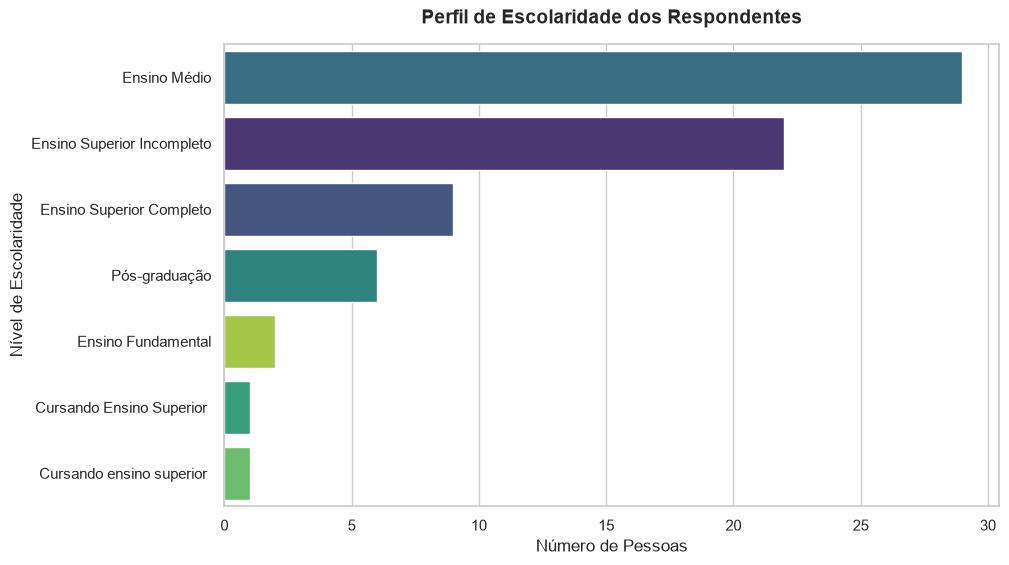

In [19]:
# Importação das bibliotecas de visualização gráfica
import matplotlib.pyplot as plt
import seaborn as sns

# Configuração do estilo visual dos gráficos (para ficarem mais elegantes)
sns.set_theme(style="whitegrid")

# ==========================================
# GRÁFICO 1: NÍVEL DE ESCOLARIDADE
# ==========================================

# Definir o tamanho da imagem do gráfico
plt.figure(figsize=(10, 6))

# Criar um gráfico de barras (countplot) baseado na coluna 'Escolaridade'
grafico_escolaridade = sns.countplot(
    data=df, 
    y='Escolaridade', 
    hue='Escolaridade',
    order=df['Escolaridade'].value_counts().index, # Ordena da maior barra para a menor
    palette="viridis" # Paleta de cores profissional
)

# Adicionar títulos e rótulos
plt.title('Perfil de Escolaridade dos Respondentes', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Número de Pessoas', fontsize=12)
plt.ylabel('Nível de Escolaridade', fontsize=12)

# Mostrar o gráfico limpo no ecrã
plt.show()

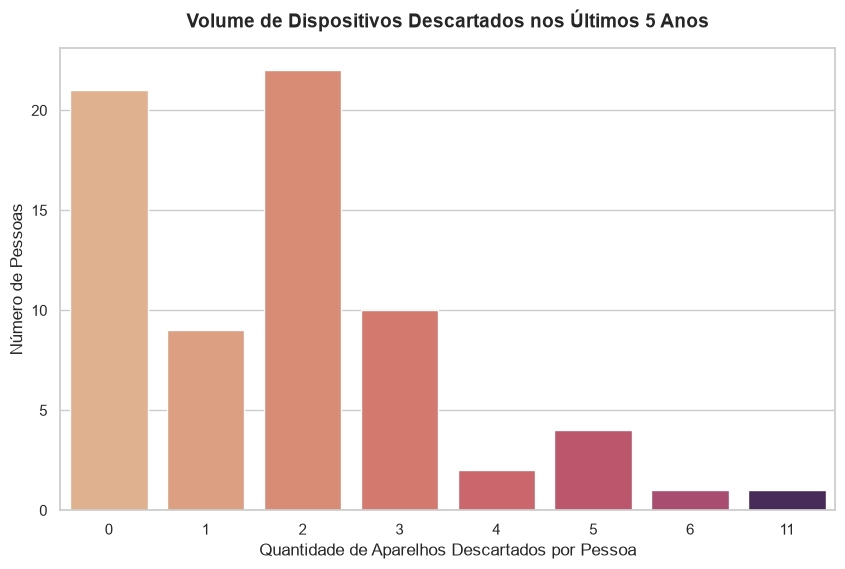

In [20]:
# ==========================================
# GRÁFICO 2: QUANTIDADE DE DISPOSITIVOS DESCARTADOS
# ==========================================

# Definir o tamanho da imagem do gráfico
plt.figure(figsize=(10, 6))

# Criar um gráfico de barras (countplot) para a quantidade descartada (no eixo X)
# Já com o 'hue' incluído para evitar aquele aviso chato!
grafico_descarte = sns.countplot(
    data=df, 
    x='Qtd_Descartada_5A', 
    hue='Qtd_Descartada_5A',
    palette="flare", # Nova paleta de cores para variar (tons de vermelho/laranja)
    legend=False # Esconde a legenda extra que não precisamos
)

# Adicionar títulos e rótulos profissionais
plt.title('Volume de Dispositivos Descartados nos Últimos 5 Anos', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Quantidade de Aparelhos Descartados por Pessoa', fontsize=12)
plt.ylabel('Número de Pessoas', fontsize=12)

# Mostrar o gráfico limpo no ecrã
plt.show()

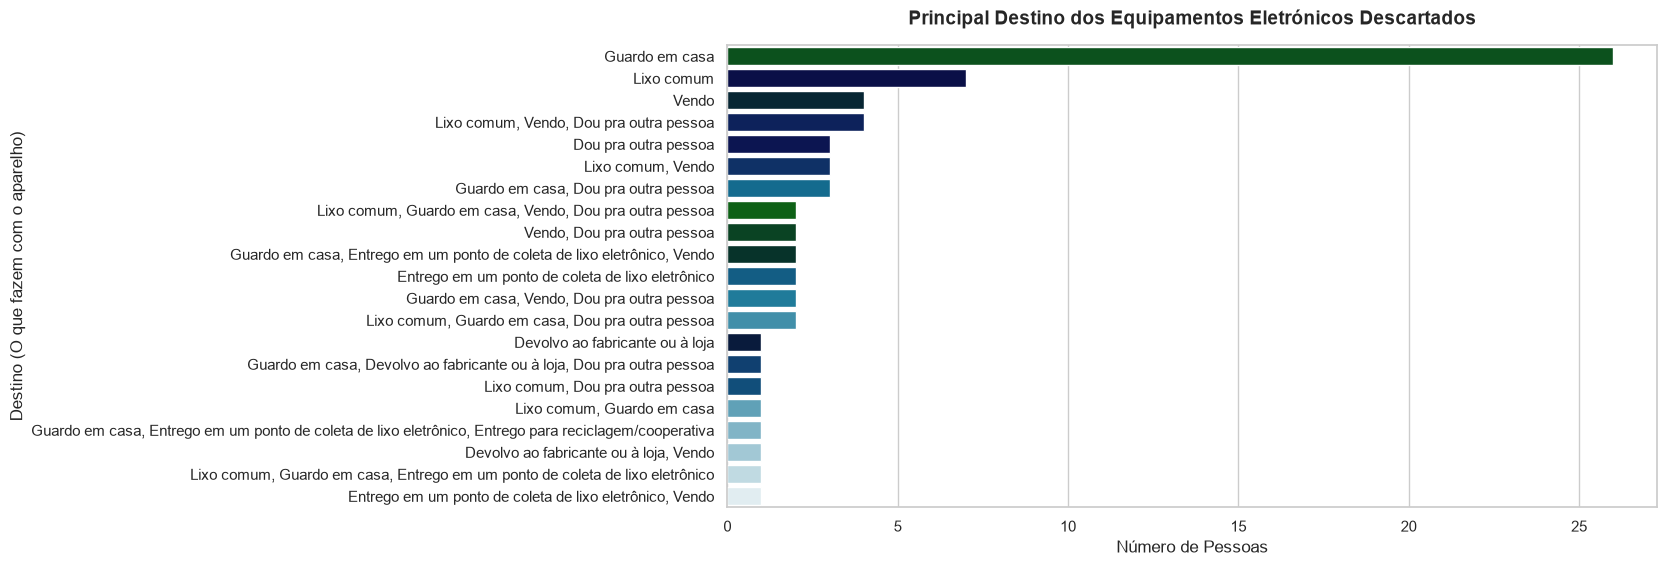

In [21]:
# ==========================================
# GRÁFICO 3: O DESTINO DO DESCARTE
# ==========================================

# Definir o tamanho da imagem
plt.figure(figsize=(12, 6))

# Criar o gráfico de barras baseado na coluna 'Destino_Descarte'
grafico_destino = sns.countplot(
    data=df, 
    y='Destino_Descarte', 
    hue='Destino_Descarte',
    order=df['Destino_Descarte'].value_counts().index, 
    palette="ocean", # Paleta em tons de azul/verde (sustentabilidade)
    legend=False
)

# Adicionar títulos
plt.title('Principal Destino dos Equipamentos Eletrónicos Descartados', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Número de Pessoas', fontsize=12)
plt.ylabel('Destino (O que fazem com o aparelho)', fontsize=12)

# Mostrar o gráfico no ecrã
plt.show()

## 5. Conclusões e Insights Principais

Com base na Análise Exploratória de Dados (EDA) realizada sobre a amostra de 70 respondentes, extraí os seguintes *insights* estratégicos sobre o comportamento de consumo e descarte de lixo eletrônico:

1. **Perfil Demográfico e Consumo:** O público é predominantemente jovem-adulto (média de 27 anos) e possui um alto nível de escolaridade (maioria com Ensino Médio ou Superior Incompleto). Observa-se um alto consumo tecnológico, com uma média de **4 dispositivos em uso simultâneo** por pessoa.
2. **Alta Rotatividade (Obsolescência):** Os dados indicam uma substituição frequente de aparelhos. O padrão predominante é o descarte de **2 dispositivos por pessoa** a cada ciclo de 5 anos.
3. **O Fenômeno da Acumulação ("Gaveta Tecnológica"):** O *insight* mais crítico da pesquisa revela que o destino primário do E-waste (Lixo Eletrônico) não é a reciclagem, mas sim a **acumulação residencial**. A maioria dos usuários prefere **guardar os aparelhos antigos em casa** em vez de dar-lhes um fim adequado, indicando uma possível falta de informação sobre pontos de coleta ou um apego ao equipamento obsoleto.

**Próximos Passos Sugeridos:**
Para mitigar o impacto ambiental, é necessário criar campanhas de conscientização focadas não apenas em "não jogar no lixo comum", mas sim em incentivar o "desapego" e a entrega de equipamentos parados nas residências para centros de reciclagem especializados.